# Does ECI predict growth? Projects 1 and 2

Maitree Mody, 2026-11-13. Answers **Project 1** (replicate the classic result) and **Project 2** (did the Atlas
predictions come true?) from `willbetts/ECI_growth_prediction.md`.

Built independently of `willbetts/nightly/` (own download, own panel code, no shared library), so it doubles as a check
on the nightly run's Q12 and Q16 results. All numbers below are printed by the cells that produce them.

## 1. Question and why it matters
- **Project 1:** Does a country's ECI predict its growth over the next decade, after controlling for how rich it already is
  and how much it earns from natural resources? This is the claim the lab's "maximize ECI" advice rests on.
- **Project 2:** In-sample fit can flatter. Harvard has published complexity-based growth forecasts for years. Were the
  ones made *before* the outcome was known actually accurate, and do they beat simple rules of thumb?

## 2. Data
| Data | Source | Coverage |
|---|---|---|
| Published ECI, COI, diversity, exports (SITC rev. 2) | Harvard Growth Lab, *International Trade Data (SITC)*, Dataverse doi:10.7910/DVN/H8SFD2 (v18), `sitc_country_year.csv` | 1962-2024 |
| Published ECI (HS92) | Growth Lab, *International Trade Data (HS92)*, doi:10.7910/DVN/T4CHWJ, `hs92_country_year.csv` | 1995-2024 |
| Growth projections, **every published edition** | Growth Lab, *Growth Projections and Complexity Rankings*, doi:10.7910/DVN/XTAQMC, versions 1.0 (2019-06-03) to 12.0 (2026-02-08) | base years 2004-2024 |
| GDP per capita (constant 2015 US$; PPP constant 2021 $), resource rents (% GDP), population, region, income group | World Bank WDI API (`NY.GDP.PCAP.KD`, `NY.GDP.PCAP.PP.KD`, `NY.GDP.TOTL.RT.ZS`, `SP.POP.TOTL`) | 1960-2024 (rents from 1970) |
| Real GDP (`rgdpna`), population | Penn World Table 10.01 | 1950-2019 |

All downloaded 2026-11-13 by `scripts/fetch_atlas.sh` and `scripts/fetch_worldbank.py`. Countries are merged on ISO3 codes.

**Sample rules (shared conventions):** population of at least 1 million at the start of each window; World Bank aggregates
dropped; the robustness section adds the $1B export filter. ECI is standardized within each window, so coefficients read
as "percentage points of annual growth per 1 SD of ECI". Standard errors are clustered by country.

In [1]:
import sys, warnings
sys.path.insert(0, 'scripts'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
import panel as P, score_forecasts as SF
from vintages import load_vintages
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)

cy = pd.read_csv(P.DERIVED / 'country_year.csv')
print('country-year panel:', cy.shape, 'countries', cy.iso3.nunique(), 'years', cy.year.min(), '-', cy.year.max())

# shared convention: ECI must correlate positively with diversity in every year
for e, d in [('eci_sitc', 'diversity_sitc'), ('eci_hs', 'diversity_hs')]:
    r = cy.groupby('year').apply(lambda g: g[e].corr(g[d]))
    print(f'{e}: corr with diversity, min over years = {r.min():.2f}; years with negative sign = {(r < 0).sum()}')

country-year panel: (14075, 20) countries 217 years 1960 - 2024
eci_sitc: corr with diversity, min over years = 0.61; years with negative sign = 0
eci_hs: corr with diversity, min over years = 0.59; years with negative sign = 0


# Project 1: Replicate the classic result

## 3. Method
One row per country and decade. For decades starting 1974, 1984, 1994, 2004 and 2014 (the last ends in 2024):

`growth(t, t+10) = b1 log GDPpc(t) + b2 resource rents + b3 ECI(t) + decade fixed effects`

- growth: annualized real GDP per capita growth, % per year (constant 2015 US$)
- resource rents: average over the decade, % of GDP (the Atlas controls for expected resource export growth over the decade; this is the closest proxy)
- ECI: Growth Lab's published SITC ECI, which is the only published series that reaches back before 1995

The headline number is **how much R² rises when ECI is added** to the income-and-resources baseline.

**Differences from the nightly Q12 run:** five decades from 1974 instead of three from 1995; SITC instead of HS ECI; no
resource-export-share control (it needs the 450 MB product file); no $1B export filter in the main spec.

**Differences from the spec's shared conventions:** the main outcome is constant-2015-US$ GDP per capita, because PPP
series start only in 1990; PPP and the $1B export filter are run as robustness checks (section 5).

**Who drops out:** Taiwan (no World Bank data); Puerto Rico and Kosovo, plus Lesotho, Botswana, Namibia and Eswatini
before 2000 (no SITC ECI; in the main decades Eswatini is excluded anyway by the 1M population rule); 26 countries without
ECI in 1974, mostly states that did not yet exist, and West Bank and Gaza in 1994; and countries without GDP at the start
or end of a window: 17 countries including Russia, Poland and Vietnam lack 1974 GDP, Eritrea lacks 2014 GDP, and Syria,
Yemen and South Sudan lack 2024 GDP. The sample therefore leans toward countries with stable statistics.

In [2]:
def fit(D, f):
    return smf.ols(f, data=D).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(D.iso3)[0]})

def build(starts, length=10, **kw):
    W = P.window_panel(cy, starts, length=length, **kw)
    return P.zscore_by(W, ['eci']).dropna(subset=['growth', 'lny0', 'rents', 'eci'])

def compare(W, label):
    b = fit(W, 'growth ~ lny0 + rents + C(start)')
    m = fit(W, 'growth ~ lny0 + rents + eci + C(start)')
    return {'spec': label, 'n': int(m.nobs), 'countries': W.iso3.nunique(), 'R2 baseline': b.rsquared,
            'R2 + ECI': m.rsquared, 'delta R2': m.rsquared - b.rsquared,
            'adj R2 baseline': b.rsquared_adj, 'adj R2 + ECI': m.rsquared_adj,
            'ECI coef (pp/yr per SD)': m.params['eci'], 'se': m.bse['eci'], 'p': m.pvalues['eci']}

DECADES = [1974, 1984, 1994, 2004, 2014]
W = build(DECADES, eci='eci_sitc')
main = fit(W, 'growth ~ lny0 + rents + eci + C(start)')
print(main.summary().tables[1])
pd.DataFrame([compare(W, 'Main: SITC ECI, 5 decades 1974-2024')])

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            6.9725      1.056      6.602      0.000       4.903       9.042
C(start)[T.1984]    -0.1184      0.320     -0.370      0.711      -0.745       0.508
C(start)[T.1994]     1.6720      0.287      5.834      0.000       1.110       2.234
C(start)[T.2004]     1.8618      0.314      5.932      0.000       1.247       2.477
C(start)[T.2014]     0.7619      0.314      2.423      0.015       0.146       1.378
lny0                -0.7540      0.129     -5.841      0.000      -1.007      -0.501
rents               -0.0136      0.016     -0.865      0.387      -0.045       0.017
eci                  1.2498      0.212      5.897      0.000       0.834       1.665


,spec,n,countries,R2 baseline,R2 + ECI,delta R2,adj R2 baseline,adj R2 + ECI,ECI coef (pp/yr per SD),se,p
0,"Main: SITC ECI, 5 decades 1974-2024",652,156,0.142,0.219,0.077,0.134,0.21,1.25,0.212,3.693e-09


## 4. Results

### 4.1 Headline and the comparison with published results
**Published benchmark.** *The Atlas of Economic Complexity* (Hausmann, Hidalgo et al. 2013), Technical Box 3.1, Table 3.1.1:
decades 1978-88, 1988-98, 1998-2008; 301 observations; controls are log initial GDP per capita, the increase in net
natural-resource exports (share of initial GDP) and decade fixed effects. **Adjusted R² goes from 0.291 to 0.472 when ECI is
added (+0.181), and a 1 SD higher ECI goes with 1.9 pp/yr faster growth.** (Liberia 1988 and Zimbabwe 1998 excluded as outliers.)

The table below runs our pipeline on the Atlas's exact decades, on our main five decades, and on the nightly run's windows.
The nightly run's Q12 main spec (`willbetts/nightly/runs/2026-11-12_Q12-atlas-growth-regression/results.json`) reported
delta R² = 0.026, ECI coefficient 0.75 per SD, p = 0.002, n = 358 (windows 1995/2004/2013, HS ECI).
Our resource control is WDI rents rather than the Atlas's natural-resource export growth, which is the main remaining difference.

In [3]:
atlas_dec = build([1978, 1988, 1998], eci='eci_sitc')
atlas_dec = atlas_dec[~(((atlas_dec.iso3 == 'LBR') & (atlas_dec.start == 1988)) | ((atlas_dec.iso3 == 'ZWE') & (atlas_dec.start == 1998)))]
# spec item: income-only vs income+ECI (no resource control)
for lab, D_ in [('Atlas decades', atlas_dec), ('Main 5 decades', W)]:
    b0 = fit(D_, 'growth ~ lny0 + C(start)'); m0 = fit(D_, 'growth ~ lny0 + eci + C(start)')
    print(f"{lab}: income-only R2 {b0.rsquared:.3f} -> income+ECI {m0.rsquared:.3f} (delta {m0.rsquared - b0.rsquared:.3f})")
rows = [{'spec': 'PUBLISHED: Atlas 2013 Table 3.1.1 (1978/1988/1998)', 'n': 301, 'adj R2 baseline': 0.291, 'adj R2 + ECI': 0.472,
         'ECI coef (pp/yr per SD)': 1.9},
        compare(atlas_dec, 'Ours on Atlas decades 1978/1988/1998 (same exclusions)'),
        compare(W, 'Main: SITC ECI, 5 decades 1974-2024'),
        compare(build([1995, 2004, 2013], eci='eci_hs', rents_avg=False), 'Q12 windows (1995/2004/2013), HS ECI, start-year rents'),
        compare(build([1995, 2004, 2013], eci='eci_sitc', rents_avg=False), 'Q12 windows, SITC ECI, start-year rents')]
pd.DataFrame(rows)

Atlas decades: income-only R2 0.131 -> income+ECI 0.276 (delta 0.145)
Main 5 decades: income-only R2 0.089 -> income+ECI 0.217 (delta 0.128)


,spec,n,adj R2 baseline,adj R2 + ECI,ECI coef (pp/yr per SD),countries,R2 baseline,R2 + ECI,delta R2,se,p
0,PUBLISHED: Atlas 2013 Table 3.1.1 (1978/1988/1...,301,0.291,0.472,1.900,NaN,NaN,NaN,NaN,NaN,NaN
1,Ours on Atlas decades 1978/1988/1998 (same exc...,352,0.160,0.265,1.648,143.0,0.170,0.276,0.106,0.295,2.303e-08
2,"Main: SITC ECI, 5 decades 1974-2024",652,0.134,0.210,1.250,156.0,0.142,0.219,0.077,0.212,3.693e-09
3,"Q12 windows (1995/2004/2013), HS ECI, start-ye...",441,0.128,0.161,0.823,154.0,0.136,0.170,0.034,0.242,6.854e-04
4,"Q12 windows, SITC ECI, start-year rents",441,0.128,0.174,0.971,154.0,0.136,0.184,0.047,0.222,1.171e-05


**Reading:** on the nightly run's own windows, our independent pipeline gets a similar answer (a small but significant
ECI effect). Our sample is larger (no resource-export-share control or export filter). Compared like for like (SITC ECI,
start-year rents), adding the decades before 1995 roughly doubles the R² gain from ECI (0.090 vs 0.047; see the
robustness table). On the Atlas's decades our ECI coefficient is close to the published one (1.65 vs 1.9). ECI raises our
adjusted R² by 0.105 (+66% adjusted, +63% unadjusted), against the Atlas's +0.181 (+62% by its table; its text says 66%),
so the proportional gain is similar but the absolute gain is about 58% of the published one, and both our R² levels are
lower. Our
resource-rents control is close to zero, unlike the Atlas's strongly significant resource-export term, which plausibly
(but untested) explains the lower R².

### 4.2 Does it hold in every decade?

,decade,n,coef,lo,hi,p,delta R2
0,1974-1984,95,1.404,0.368,2.439,7.884e-03,0.099
1,1984-1994,112,1.617,0.692,2.543,6.144e-04,0.111
2,1994-2004,142,1.623,0.922,2.324,5.684e-06,0.141
3,2004-2014,150,0.476,-0.081,1.033,9.418e-02,0.013
4,2014-2024,153,1.117,0.359,1.875,3.866e-03,0.075


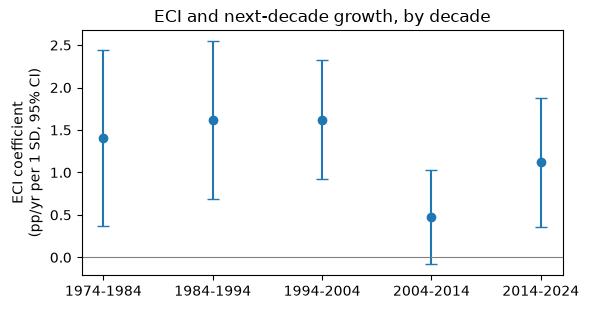

In [4]:
per = []
for s in DECADES:
    d = W[W.start == s]
    b = smf.ols('growth ~ lny0 + rents', d).fit(cov_type='HC1')
    m = smf.ols('growth ~ lny0 + rents + eci', d).fit(cov_type='HC1')
    per.append({'decade': f'{s}-{s+10}', 'n': int(m.nobs), 'coef': m.params['eci'], 'lo': m.conf_int().loc['eci', 0],
                'hi': m.conf_int().loc['eci', 1], 'p': m.pvalues['eci'], 'delta R2': m.rsquared - b.rsquared})
per = pd.DataFrame(per)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(per.decade, per.coef, yerr=[per.coef - per.lo, per.hi - per.coef], fmt='o', capsize=4)
ax.axhline(0, color='grey', lw=0.8); ax.set_ylabel('ECI coefficient\n(pp/yr per 1 SD, 95% CI)')
ax.set_title('ECI and next-decade growth, by decade'); fig.tight_layout(); fig.savefig('outputs/p1_coef_by_decade.png', dpi=120)
per

**Reading:** the ECI coefficient is positive in all five decades and significant at 1% in four of them. The exception is
2004-2014 (commodity boom: resource exporters with low ECI grew fast), and the effect comes back in 2014-2024. So "the ECI-growth link weakened after 2005" (nightly
proposal 3) looks like one unusual decade in this longer panel, not a lasting decline.

### 4.3 Is it driven by one region, or does it differ by income?
The Atlas reports that ECI matters more for poorer countries. We test this with an ECI x log income interaction, and check
whether any single region drives the result.

In [5]:
W['lny0c'] = W.lny0 - W.lny0.mean(); W['eci_x_income'] = W.eci * W.lny0c
inter = fit(W, 'growth ~ lny0 + rents + eci + eci_x_income + C(start)')
print(f"ECI x log GDPpc interaction: {inter.params['eci_x_income']:.3f} (se {inter.bse['eci_x_income']:.3f}, p = {inter.pvalues['eci_x_income']:.3f})")

rows = []
for r in sorted(W.region.unique()):
    m = fit(W[W.region != r], 'growth ~ lny0 + rents + eci + C(start)')
    rows.append({'sample': f'without {r}', 'n': int(m.nobs), 'coef': m.params['eci'], 'p': m.pvalues['eci']})
# income terciles at the START of each decade (today's WB groups would condition on the outcome: fast growers moved up)
W['inc_tercile'] = W.groupby('start').lny0.transform(lambda s: pd.qcut(s, 3, labels=['poorest third', 'middle third', 'richest third']))
for g in ['poorest third', 'middle third', 'richest third']:
    m = fit(W[W.inc_tercile == g], 'growth ~ lny0 + rents + eci + C(start)')
    rows.append({'sample': f'only {g} of start-year income', 'n': int(m.nobs), 'coef': m.params['eci'], 'p': m.pvalues['eci']})
pd.DataFrame(rows)

ECI x log GDPpc interaction: 0.026 (se 0.089, p = 0.769)


,sample,n,coef,p
0,without East Asia & Pacific,570,1.196,7.048e-09
1,without Europe & Central Asia,482,1.144,1.700e-06
2,without Latin America & Caribbean,542,1.318,5.817e-09
3,"without Middle East, North Africa, Afghanistan...",572,1.300,2.793e-08
4,without North America,642,1.247,4.238e-09
5,without South Asia,632,1.262,1.216e-08
6,without Sub-Saharan Africa,472,1.024,2.037e-04
7,only poorest third of start-year income,219,1.138,1.619e-03
8,only middle third of start-year income,216,1.336,1.713e-06
9,only richest third of start-year income,217,1.196,7.727e-03


**Reading:** no single region drives the result, East Asia included. The interaction is essentially zero: in this
panel ECI predicts growth about equally for rich and poor countries, which does **not** reproduce the Atlas finding that
it matters more for poorer ones. Splitting by start-of-decade income terciles gives similar coefficients in each third.

### 4.4 "ECI gap": did countries that were complex for their income grow fastest?
The ECI gap is the residual from regressing ECI on log GDP per capita within each decade. A positive gap means more
complex than the country's income would suggest.

In [6]:
W['eci_gap'] = W.groupby('start', group_keys=False).apply(lambda d: smf.ols('eci ~ lny0', d).fit().resid)
W['gap_quintile'] = W.groupby('start').eci_gap.transform(lambda s: pd.qcut(s, 5, labels=[1, 2, 3, 4, 5]))
q = W.groupby('gap_quintile', observed=True).agg(n=('growth', 'size'), mean_growth=('growth', 'mean'), median_growth=('growth', 'median'))
print(q)
t = stats.ttest_ind(W[W.gap_quintile == 5].growth, W[W.gap_quintile == 1].growth, equal_var=False)
g = fit(W, 'growth ~ lny0 + rents + eci_gap + C(start)')
print(f"top vs bottom quintile: difference {W[W.gap_quintile == 5].growth.mean() - W[W.gap_quintile == 1].growth.mean():.2f} pp/yr, Welch p = {t.pvalue:.2g}")
print(f"continuous: growth on ECI gap (with income, rents, decade FE): coef {g.params['eci_gap']:.2f}, p = {g.pvalues['eci_gap']:.2g}")
top =W.sort_values('eci_gap', ascending=False).groupby('start').head(5)[['start', 'name', 'eci_gap', 'growth']]
top

                n  mean_growth  median_growth
gap_quintile                                 
1             132        0.087          0.447
2             129        1.549          1.226
3             130        2.069          1.901
4             129        1.921          1.838
5             132        2.711          2.539
top vs bottom quintile: difference 2.62 pp/yr, Welch p = 2.6e-12
continuous: growth on ECI gap (with income, rents, decade FE): coef 1.27, p = 2.5e-09


,start,name,eci_gap,growth
897,2014,Central African Republic,2.049,1.036
318,1984,Cambodia,1.582,-2.677
305,1984,India,1.453,2.945
453,1994,Bosnia and Herzegovina,1.432,12.573
89,1974,India,1.416,2.068
36,1974,China,1.403,6.356
252,1984,China,1.346,8.452
521,1994,India,1.293,4.162
821,2004,Sierra Leone,1.292,2.183
738,2004,India,1.222,5.086


**Reading:** the table shows average growth by ECI-gap quintile (1 = least complex for its income, 5 = most). The pattern
rises overall but is not perfectly monotonic (quintile 3 is slightly above 4). The second table lists the five
largest-gap countries in each decade; several are small or conflict-era exporters (e.g. Central African Republic 2014,
Bosnia 1994), which is a reason to also check the $1B export filter (section 5).

## 5. Robustness

In [7]:
rows = [compare(W, 'Main'),
        compare(build(DECADES, eci='eci_sitc', rents_avg=False), 'Start-year resource rents (strictly ex ante)'),
        compare(build(DECADES, eci='eci_sitc', min_exports=1e9), 'Exports >= $1B at start'),
        compare(build([1969, 1979, 1989, 1999, 2009], eci='eci_sitc', gdp='gdppc_pwt'), 'Penn World Table GDPpc, decades 1969-2019'),
        compare(build([1994, 2004, 2014], eci='eci_sitc', gdp='gdppc_ppp_const'), 'PPP GDPpc, decades 1994-2024'),
        compare(build(list(range(1974, 2020, 5)), length=5, eci='eci_sitc'), '5-year windows 1974-2024'),
        compare(build([1974, 1984, 1994, 2014], eci='eci_sitc'), 'Drop 2004-2014')]
fe = fit(W, 'growth ~ lny0 + rents + eci + C(start) + C(iso3)')
rob = pd.DataFrame(rows)
print(f"Within-country (country fixed effects): ECI coef = {fe.params['eci']:.2f}, se = {fe.bse['eci']:.2f}, p = {fe.pvalues['eci']:.3f}")
rob

Within-country (country fixed effects): ECI coef = 0.61, se = 0.36, p = 0.094


,spec,n,countries,R2 baseline,R2 + ECI,delta R2,adj R2 baseline,adj R2 + ECI,ECI coef (pp/yr per SD),se,p
0,Main,652,156,0.142,0.219,0.077,0.134,0.210,1.250,0.212,3.693e-09
1,Start-year resource rents (strictly ex ante),633,155,0.126,0.217,0.090,0.118,0.208,1.337,0.214,4.220e-10
2,Exports >= $1B at start,471,139,0.174,0.292,0.119,0.163,0.282,1.516,0.246,7.104e-10
3,"Penn World Table GDPpc, decades 1969-2019",590,148,0.140,0.185,0.045,0.131,0.175,0.976,0.288,7.008e-04
4,"PPP GDPpc, decades 1994-2024",436,152,0.123,0.182,0.058,0.115,0.172,1.001,0.243,3.760e-05
5,5-year windows 1974-2024,1304,156,0.100,0.151,0.051,0.093,0.143,1.284,0.214,1.958e-09
6,Drop 2004-2014,502,156,0.145,0.246,0.101,0.136,0.237,1.443,0.228,2.657e-10


**Reading:** the ECI effect survives every variation of outcome, window and sample. It weakens and loses conventional
significance only with **country fixed effects**, the within-country test: countries do not clearly grow faster in the
decades after *their own* ECI rises. That is the causal question (Project 4), and it is the one that matters most for the
lab's "raise your ECI" advice.

# Project 2: Did the Atlas predictions come true?

## 3. Method
- **Forecasts:** every published version of the Growth Lab's growth projections on Dataverse: 13 versions from June 2019
  to February 2026, of which 9 are distinct files (v1.0 = v2.0 = v2.1, v5.0 = v6.0 and v10.0 = v11.0 are identical).
  Each gives, for each country and base year, a forecast of annualized growth over the following decade.
- **Real-time test:** the June 2019 edition's forecasts for base year 2017. They were released on 2019-06-03, before
  2019-2024 was observed (2018 existed only as preliminary data), so scoring them on realized 2017-2024 growth (7 of the
  10 forecast years) is close to a true out-of-sample test.
- **Benchmarks the forecast must beat**, each built only from years up to 2017 (fitting sample: population >= 1M):
  naive (every country grows at the 2007-2017 average of the fitting sample), persistence (each country repeats its own
  2007-2017 growth), income only (2007-2017 growth on 2007 log income: the spec's convergence benchmark), convergence
  (income plus resource rents), and income+ECI (plus 2007 ECI: our own simple complexity model). Rents at the forecast
  date are each country's mean over the available years in 2008-2017 (the fit uses 2007-2016 means).
- **Scores:** Pearson and Spearman correlation with realized growth, mean absolute error (MAE), RMSE, bias, and the
  share of countries placed in the correct growth tercile (undefined for the constant naive forecast). Paired tests on
  per-country absolute and squared errors.
- **Caveats:** benchmarks use today's revised data and today's ECI release, not what was available in 2019. Realized
  growth is a log rate; if `growth_proj` is a compound rate, it reads about g²/2 higher (about 0.2 pp at 6%).

### 4.1 What does `growth_proj` measure, and were forecasts revised?
The data dictionary says "forecasted annualized rate of growth for following decade" without saying whether it is total
GDP or GDP per capita. We compare its level with both, and compare consecutive editions for every base year.

In [8]:
V = load_vintages()
res = SF.main()
bc = res['backcasts']
print('Backcasts 2004-2014 (June 2019 edition), mean over base years:')
print(bc.groupby('outcome')[['pearson', 'mae', 'bias']].mean())
print()
# If growth_proj were per-capita growth plus population growth, it would load about 1:1 on population growth
G = 'Growth Lab (2019 edition)'; D = res['realtime_total']
a0 = cy[cy.year == 2007].set_index('iso3').population; a1 = cy[cy.year == 2017].set_index('iso3').population
pl = pd.DataFrame({'proj': D[G], 'popg': P.ann_growth(a0, a1.reindex(a0.index), 10).reindex(D.index)}).dropna()
pm = smf.ols('proj ~ popg', pl).fit(cov_type='HC1')
print(f"2017 forecast on 2007-2017 population growth: slope {pm.params['popg']:.3f} (se {pm.bse['popg']:.3f}), R2 {pm.rsquared:.3f}, n {int(pm.nobs)}")
print()
print('Coverage changes between consecutive editions (rows added/removed):')
display(res['coverage'])
print('Every VALUE revision between consecutive editions (base years not listed never changed value):')
res['revisions']

Backcasts 2004-2014 (June 2019 edition), mean over base years:
         pearson    mae   bias
outcome                       
pc         0.270  2.189  1.587
total      0.395  1.654  0.318

2017 forecast on 2007-2017 population growth: slope 0.083 (se 0.084), R2 0.009, n 133

Coverage changes between consecutive editions (rows added/removed):


,from,to,rows added,rows removed,removed (examples)
0,v2.1_2019-08-20,v3.0_2022-07-28,399,0,[]
1,v3.0_2022-07-28,v4.0_2023-07-28,133,0,[]
2,v4.0_2023-07-28,v5.0_2024-09-17,158,6,"[(ROU, 2016), (ROU, 2017), (ROU, 2018), (ROU, ..."
3,v6.0_2024-09-17,v7.0_2025-03-31,154,0,[]
4,v7.0_2025-03-31,v8.0_2025-06-10,50,0,[]
5,v8.0_2025-06-10,v9.0_2025-06-10,0,52,"[(ABW, 2023), (AND, 2023), (ATG, 2023), (BDI, ..."
6,v11.0_2025-08-21,v12.0_2026-02-08,143,0,[]


Every VALUE revision between consecutive editions (base years not listed never changed value):


,from,to,base_year,countries changed,mean |change|,max |change|
0,v3.0_2022-07-28,v4.0_2023-07-28,2019,121,0.003,0.005
1,v6.0_2024-09-17,v7.0_2025-03-31,2022,144,0.614,3.151
2,v7.0_2025-03-31,v8.0_2025-06-10,2023,145,0.091,0.417


**Reading:** against per-capita growth the forecasts run well above what happened (bias about 1.6 pp, roughly population
growth); against total GDP growth the bias is small and the correlation higher. That **suggests** `growth_proj` is a
total-GDP forecast, but the evidence cuts both ways: the dictionaries never say, and the forecasts barely load on past
population growth (slope printed above, far from the ~1 a per-capita-plus-population forecast would show). We score
against total GDP growth in the main table, and per-capita growth in the robustness section, where the conclusion flips.

Forecast values for base years 2004-2018, 2020 and 2021 are identical in every edition that contains them (2018 and 2020
appear from the 2022 edition, 2021 from 2023; 2024 only in the 2026 edition). Some editions add or drop countries (e.g.
Romania's base years 2016-2021 are missing from the 2024 editions and restored later with the same values; the June
2025 edition drops 50 unranked base-2023 rows plus Lesotho and South Sudan 2021). Three base years were revised:
2019 (2023 edition, negligible), 2022 (March 2025 edition: 144 countries, mean change 0.61 pp, max 3.15) and 2023
(June 2025 edition, mean 0.09 pp). The 2004-2016 forecasts first appear in the 2019 edition; Dataverse alone cannot show
whether each was published at the time, so only base 2017 is treated as real-time.

### 4.2 Real-time scorecard: June 2019 edition, 2017-2024

In [9]:
D = res['realtime_total']
gl_vint = V[(V.vintage == 'v1.0_2019-06-03') & (V.base_year == 2017)].iso3
print('countries with a 2017 forecast:', gl_vint.nunique(), '| scored:', len(D.dropna()),
      '| dropped (missing column):', SF.dropped(D))
SF.scorecard(D)

countries with a 2017 forecast: 133 | scored: 132 | dropped (missing column): {'YEM': ['actual']}


,n,pearson,spearman,mae,rmse,bias,tercile_hit
forecast,,,,,,,
Growth Lab (2019 edition),132,0.491,0.483,1.559,2.172,0.952,0.462
naive,132,NaN,NaN,1.714,2.388,0.851,NaN
persistence,132,0.551,0.541,1.641,2.338,0.884,0.576
income only,132,0.205,0.280,1.765,2.585,0.496,0.432
convergence,132,0.269,0.341,1.639,2.413,0.539,0.432
income+ECI,132,0.283,0.356,1.610,2.375,0.505,0.439


In [10]:
# negative differences = Growth Lab error smaller than the benchmark's. Caveat: tests assume per-country differences are
# independent (common shocks like Covid make p-values optimistic), and squared-error tests are outlier-driven.
SF.paired_tests(D)

,benchmark,n,mean |err| diff,"p (abs, t-test)","p (abs, Wilcoxon)",mean sq err diff,"p (squared, t-test)"
0,naive,132,-0.155,0.075,0.036,-0.987,0.156
1,persistence,132,-0.082,0.525,0.444,-0.751,0.410
2,income only,132,-0.205,0.131,0.208,-1.967,0.025
3,convergence,132,-0.080,0.497,0.578,-1.103,0.150
4,income+ECI,132,-0.051,0.656,0.776,-0.926,0.215


,country,forecast,actual,miss
iso3,,,,
VEN,"Venezuela, RB",0.80,-10.271,-11.071
LBN,Lebanon,1.09,-7.020,-8.110
MMR,Myanmar,6.36,-0.843,-7.203
LKA,Sri Lanka,4.74,-0.480,-5.220
UKR,Ukraine,2.40,-2.552,-4.952
TUN,Tunisia,5.00,0.548,-4.452
THA,Thailand,4.86,1.317,-3.543
COD,"Congo, Dem. Rep.",2.05,5.210,3.160
OMN,Oman,4.49,1.423,-3.067


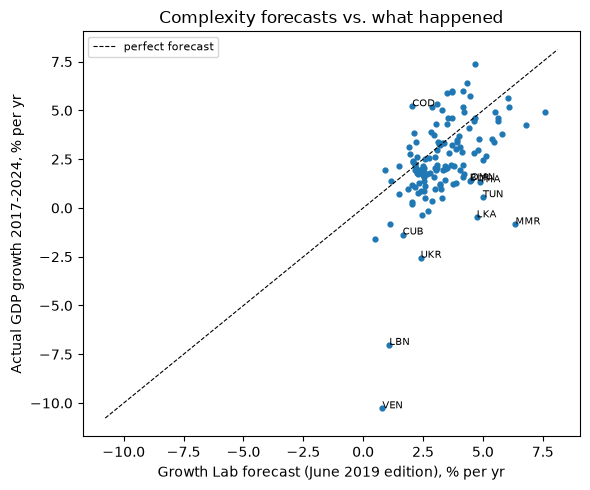

In [11]:
names = cy[cy.year == 2017].set_index('iso3').name
G = 'Growth Lab (2019 edition)'
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(D[G], D.actual, s=12)
lim = [min(D[G].min(), D.actual.min()) - 0.5, max(D[G].max(), D.actual.max()) + 0.5]
ax.plot(lim, lim, 'k--', lw=0.8, label='perfect forecast')
miss = (D.actual - D[G]).rename('miss')
for iso in miss.abs().sort_values().index[-12:]:
    ax.annotate(iso, (D.loc[iso, G], D.loc[iso, 'actual']), fontsize=7)
ax.set_xlabel('Growth Lab forecast (June 2019 edition), % per yr'); ax.set_ylabel('Actual GDP growth 2017-2024, % per yr')
ax.set_title('Complexity forecasts vs. what happened'); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig('outputs/p2_forecast_vs_actual.png', dpi=120)
pd.DataFrame({'country': names.reindex(D.index), 'forecast': D[G], 'actual': D.actual, 'miss': miss}).reindex(
    miss.abs().sort_values(ascending=False).index).head(15)

**Reading:** the largest misses are listed above (actual minus forecast; negative = grew slower than forecast).

**Why the ten biggest misses happened** (forecast and actual numbers come from the table above; background from the
sources linked; checked 2026-11-13):

| Country | Miss (pp/yr) | What happened |
|---|---|---|
| Venezuela | -11.1 | Economic collapse: oil output fell for five straight years (down 44.5% in 2019 alone), hyperinflation from 2016-17, and US financial sanctions from 2017; ECLAC estimates GDP fell 62% from 2013 to 2019. ([ECLAC](https://repositorio.cepal.org/server/api/core/bitstreams/31ee36aa-e1dc-44ae-ad17-6d3eb49cf7e9/content)) |
| Lebanon | -8.1 | Banking and currency collapse from late 2019 (deposits frozen), then the August 2020 Beirut port explosion; the World Bank ranks it among the worst crises globally since the 1850s. ([World Bank](https://www.worldbank.org/en/country/lebanon/overview), [Al Jazeera](https://www.aljazeera.com/amp/economy/2020/12/1/deliberate-depression-world-banks-dire-warning-on-lebanon)) |
| Myanmar | -7.2 | February 2021 military coup on top of Covid; the World Bank estimated an 18% contraction in fiscal 2021 and described the economy as "permanently scarred". ([VOA](https://www.voanews.com/a/economy-business_world-bank-coup-and-coronavirus-shrink-myanmars-economy-18/6208716.html), [The Diplomat](https://thediplomat.com/2023/06/military-coup-has-inflicted-permanent-damage-on-myanmar-world-bank-says)) |
| Sri Lanka | -5.2 | Foreign-exchange and debt crisis ending in the country's first sovereign default (April 2022); GDP fell 7.3% in 2022 and 2.3% in 2023. ([World Bank](https://www.worldbank.org/en/news/press-release/2022/10/06/debt-restructuring-and-implementation-of-deep-reforms-critical-for-sri-lanka-s-economic-stabilization), [Wikipedia](https://en.wikipedia.org/wiki/Sri_Lanka_sovereign_default)) |
| Ukraine | -5.0 | Russia's full-scale invasion in February 2022; GDP fell 37% year on year in Q2 2022 (the World Bank had forecast a 45% annual fall). ([BOFIT](https://bofit.fi/en/monitoring/weekly/2023/vw202305_1), [Bloomberg](https://www.bloomberg.com/news/articles/2022-04-10/ukraine-economy-to-fall-45-in-2022-russia-11-world-bank-says)) |
| Tunisia | -4.5 | A deep Covid contraction in 2020, then one of the slowest recoveries in MENA (drought, tight financing, slow reform); GDP was still below its pre-Covid level in 2024. ([World Bank](https://www.worldbank.org/en/news/press-release/2024/05/08/tunisia-s-sustained-recovery-requires-quick-action-to-take-advantage-of-opportunities)) |
| Thailand | -3.5 | Tourism-dependent economy hit by the near halt in arrivals from March 2020 (GDP -6.1% in 2020), then a weak recovery averaging about 2.3% in 2022-24. ([World Bank](https://www.worldbank.org/en/country/thailand/overview), [Al Jazeera](https://www.aljazeera.com/economy/2024/4/1/thailands-economy-stumbles-as-philippines-vietnam-indonesia-race-ahead)) |
| DR Congo | **+3.2** | The one big upside miss: a copper and cobalt boom (the Kamoa-Kakula mine from 2021); growth averaged 7.9% in 2021-23. ([World Bank](https://www.worldbank.org/en/news/press-release/2025/07/28/in-democratic-republic-of-congo-drc-reassessing-tax-incentives-can-assist-growth-and-equity), [Standard Bank](https://impact.standardbank.com/?p=1889)) |
| Oman | -3.1 | Oil exporter held back by OPEC+ production cuts (joined in 2017), fiscal austerity, and the 2020 oil-price collapse with Covid. ([IMF](https://www.imf.org/en/news/articles/2021/02/11/mcs021221oman-staff-concluding-statement-of-an-imf-staff-visit), [World Bank](https://thedocs.worldbank.org/en/doc/c2647a7e3ae716d5940d6b186e0e2f08-0280012021/original/Oman-Economic-Update-October-2021.pdf)) |
| Belarus | -3.1 | Western sanctions over its role in Russia's 2022 war on Ukraine cut exports; official GDP fell 4.7% in 2022. ([OSW](https://www.osw.waw.pl/en/publikacje/osw-commentary/2023-03-22/a-crisis-rather-a-disaster-belarusian-economy-a-year-russias), [SCEEUS](https://www.ui.se/globalassets/ui.se-eng/publications/sceeus/the-belarusian-economy-under-sanctions-since-the-start-of-russias-war-in-ukraine.pdf)) |

**Pattern:** six of the ten are political or financial crises that no trade-based model can see coming (economic
collapse, a banking crash, a coup, a sovereign default, war and sanctions). Two are tourism economies hit by Covid
(Tunisia, Thailand), and two are driven by commodities (Oman's oil cuts; DR Congo's mining boom). This motivates the
optional extension: test whether misses are systematically larger for oil exporters or Covid-exposed economies.

### 4.3 Before Covid: 2017-2019 only
This scores 10-year forecasts against 2-year realized growth, so it tests short-run tracking, not the 10-year claim; 2018
was also partly observable (preliminary data) at release. Shown with and without Venezuela (-27%/yr in 2017-2019).

In [12]:
P0 = res['precovid_total']
display(SF.scorecard(P0))
display(SF.paired_tests(P0))
print('without Venezuela:')
SF.paired_tests(P0, exclude=['VEN'])

,n,pearson,spearman,mae,rmse,bias,tercile_hit
forecast,,,,,,,
Growth Lab (2019 edition),132,0.480,0.536,1.651,3.108,0.533,0.485
naive,132,NaN,NaN,1.993,3.489,0.433,NaN
persistence,132,0.480,0.453,1.924,3.146,0.466,0.530
income only,132,0.065,0.142,2.321,3.777,0.077,0.379
convergence,132,0.145,0.223,2.111,3.587,0.120,0.402
income+ECI,132,0.164,0.248,2.080,3.550,0.087,0.409


,benchmark,n,mean |err| diff,"p (abs, t-test)","p (abs, Wilcoxon)",mean sq err diff,"p (squared, t-test)"
0,naive,132,-0.341,9.002e-05,1.691e-04,-2.514,2.923e-02
1,persistence,132,-0.273,3.679e-02,1.280e-02,-0.239,8.953e-01
2,income only,132,-0.670,4.648e-07,1.845e-06,-4.606,1.143e-04
3,convergence,132,-0.459,6.401e-05,1.769e-04,-3.203,8.540e-04
4,income+ECI,132,-0.429,1.232e-04,3.886e-04,-2.938,8.658e-04


without Venezuela:


,benchmark,n,mean |err| diff,"p (abs, t-test)","p (abs, Wilcoxon)",mean sq err diff,"p (squared, t-test)"
0,naive,131,-0.325,1.571e-04,2.596e-04,-1.459,1.042e-03
1,persistence,131,-0.308,1.553e-02,7.704e-03,-1.929,3.715e-03
2,income only,131,-0.659,7.608e-07,2.876e-06,-3.697,1.068e-06
3,convergence,131,-0.450,9.478e-05,2.550e-04,-2.475,6.043e-05
4,income+ECI,131,-0.421,1.756e-04,5.549e-04,-2.297,1.230e-04


### 4.4 Does forecast skill depend on the base year?
The 2004-2014 forecasts (first seen in the 2019 edition) can be scored on full 10-year windows. Treat these as
backcasts, not real-time forecasts.

In [13]:
bc[bc.outcome == 'total'][['base_year', 'n', 'pearson', 'spearman', 'mae', 'bias', 'tercile_hit']]

,base_year,n,pearson,spearman,mae,bias,tercile_hit
1,2004,121,0.275,0.259,1.859,-0.378,0.397
3,2005,121,0.287,0.322,1.807,-0.205,0.421
5,2006,121,0.358,0.379,1.782,0.048,0.421
7,2007,121,0.424,0.459,1.715,0.264,0.430
9,2008,121,0.448,0.496,1.653,0.222,0.471
11,2009,120,0.441,0.480,1.494,-0.075,0.508
13,2010,120,0.431,0.462,1.753,0.873,0.533
15,2011,120,0.405,0.528,1.541,0.677,0.533
17,2012,120,0.439,0.502,1.545,0.650,0.525
19,2013,120,0.392,0.456,1.569,0.731,0.558


### 4.5 Rolling-origin refit (spec step 5): does our ECI regression forecast out of time?
Harvard's forecasts give one real-time test. To get more, we pretend to stand at 1984, 1994, 2004 and 2014. At each
origin we fit the Project 1 regression using only decades that had **ended** by then, forecast growth over the next
decade from values observed at the origin, and score the forecasts against what happened.

- Models: naive (the last training decade's mean growth), persistence (each country's own previous-decade growth), income
  only, convergence (income + rents), **+ECI** (income + rents + ECI), and +diversity (income + rents + number of
  products with RCA >= 1, the simple-count alternative).
- Regressors are ex ante: rents are the mean of the 3 years up to each decade's start; ECI and diversity are standardized
  within each start-year cross-section.
- The common growth term for the forecast decade is set to the last training decade's (the Atlas's own forecasting
  assumption). Each model estimates its own decade effects, so this choice moves each model's error level differently;
  the robustness table also uses the average training decade effect, and a ranking-only score that removes levels.
- Countries need GDP 10 years before the origin (for the persistence benchmark), which drops 29 test cases, mostly
  transition economies in 1994 (Russia, Poland, Ukraine, Kazakhstan); the robustness table scores the regression models
  without this requirement.
- Out-of-sample R² vs convergence = 1 - SSE(model) / SSE(convergence); positive means the model beats income + rents.
- Paired tests pool all origins and cluster by country.

In [14]:
import rolling_origin as RO
ro = RO.main()
print(ro['forecasts'].groupby('origin').agg(countries_forecast=('actual', 'size'), training_rows=('n_train', 'first')))
ro['per_origin'].pivot(index='origin', columns='model', values='oos R2 vs convergence')[['income only', '+diversity', '+ECI', 'naive', 'persistence']]

        countries_forecast  training_rows
origin                                   
1984                    98             93
1994                   115            198
2004                   147            332
2014                   151            481


model,income only,+diversity,+ECI,naive,persistence
origin,,,,,
1984,-0.034,0.103,0.179,2.942e-04,-0.285
1994,0.086,0.028,0.051,9.583e-02,-1.095
2004,0.058,-0.013,-0.054,4.932e-02,-0.185
2014,-0.106,0.053,0.114,-1.217e-01,-0.441


In [15]:
ro['pooled'].set_index('model')

,n,pearson,spearman,mae,rmse,bias,oos R2 vs convergence,share of origins better than convergence
model,,,,,,,,
naive,511,0.032,-0.053,1.962,2.632,0.017,0.003,0.75
persistence,511,0.269,0.331,2.197,3.239,0.042,-0.509,0.00
income only,511,0.029,0.043,1.958,2.638,-0.004,-0.001,0.50
convergence,511,0.139,0.193,1.877,2.637,-0.048,0.000,0.00
+ECI,511,0.282,0.275,1.843,2.539,-0.134,0.073,0.75
+diversity,511,0.234,0.234,1.862,2.580,-0.087,0.042,0.75


In [16]:
# positive 'mean diff' = +ECI has the larger error
ro['tests']

,compare,n,mean sq diff,p (sq),mean abs diff,p (abs)
0,+ECI vs convergence,511,-0.505,0.065,-0.033,3.697e-01
1,+ECI vs income only,511,-0.512,0.117,-0.115,1.467e-02
2,+ECI vs naive,511,-0.483,0.149,-0.119,1.522e-02
3,+ECI vs +diversity,511,-0.211,0.360,-0.019,6.010e-01
4,+ECI vs persistence,511,-4.046,0.001,-0.353,4.685e-05


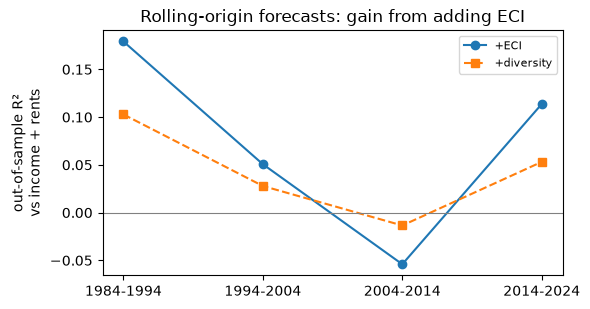

In [17]:
piv = ro['per_origin'].pivot(index='origin', columns='model', values='oos R2 vs convergence')
fig, ax = plt.subplots(figsize=(6, 3.2))
for m, mk in [('+ECI', 'o-'), ('+diversity', 's--')]:
    ax.plot([f'{T}-{T+10}' for T in piv.index], piv[m], mk, label=m)
ax.axhline(0, color='grey', lw=0.8); ax.set_ylabel('out-of-sample R²\nvs income + rents')
ax.set_title('Rolling-origin forecasts: gain from adding ECI'); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig('outputs/p2_rolling_origin.png', dpi=120)

In [18]:
# robustness: training window, sample, and the common growth term
rows = []
for lab, kw in [('main (expanding window)', {}), ('train on last decade only', {'train_mode': 'last'}), ('exports >= $1B', {'min_exports': 1e9}),
                ('average decade effect as common term', {'common': 'mean'}), ('no persistence requirement (n larger)', {'require_persistence': False})]:
    r = RO.main(**kw); p = r['pooled'].set_index('model'); t = r['tests'].set_index('compare')
    per = r['per_origin'][r['per_origin'].model == '+ECI'].set_index('origin')['oos R2 vs convergence']
    rows.append({'spec': lab, 'n': int(p.loc['+ECI', 'n']), 'oos R2 +ECI': p.loc['+ECI', 'oos R2 vs convergence'],
                 'oos R2 +diversity': p.loc['+diversity', 'oos R2 vs convergence'],
                 'origins where +ECI > 0': f"{int((per > 0).sum())} of {len(per)}",
                 'p (sq) +ECI vs convergence': t.loc['+ECI vs convergence', 'p (sq)'],
                 'p (abs) +ECI vs convergence': t.loc['+ECI vs convergence', 'p (abs)']})
F = ro['forecasts']
rows.append({'spec': 'ranking only (forecasts and outcomes demeaned within origin)', 'n': len(F),
             'oos R2 +ECI': RO.score_demeaned(F, '+ECI', 'convergence'), 'oos R2 +diversity': RO.score_demeaned(F, '+diversity', 'convergence')})
pd.DataFrame(rows)

,spec,n,oos R2 +ECI,oos R2 +diversity,origins where +ECI > 0,p (sq) +ECI vs convergence,p (abs) +ECI vs convergence
0,main (expanding window),511,0.073,0.042,3 of 4,0.065,0.370
1,train on last decade only,511,0.048,0.032,3 of 4,0.208,0.738
2,exports >= $1B,399,0.102,0.021,3 of 4,0.097,0.525
3,average decade effect as common term,511,0.048,0.032,3 of 4,0.246,0.875
4,no persistence requirement (n larger),540,0.089,0.047,3 of 4,0.023,0.223
5,ranking only (forecasts and outcomes demeaned ...,511,0.085,0.048,NaN,NaN,NaN


**How concentrated is the gain?** Out-of-sample R² is driven by squared errors, so a few large misses can dominate.
Below: the country-decades contributing most to +ECI's gain over income + rents, and the gain after dropping the most
extreme cases (largest absolute difference in squared error, either direction).

In [19]:
display(RO.top_contributors(F, '+ECI', 'convergence'))
print('top 8 share of total gain:', round(RO.top_contributors(F, '+ECI', 'convergence').iloc[:, -1].sum(), 2))
print('oos R2 after dropping the k most extreme cases:', {k: round(RO.trimmed_oos(F, '+ECI', 'convergence', k), 3) for k in (0, 5, 10, 20)})
print('naive vs convergence (does income + rents itself beat a constant?):', round(RO.oos_r2(F, 'naive', 'convergence'), 3))

,iso3,name,origin,actual,convergence,+ECI,gain,share of total gain
151,IRQ,Iraq,1994,5.242,-5.146,-2.097,54.053,0.209
481,SDN,Sudan,2014,-8.155,2.772,0.806,39.114,0.152
506,VEN,"Venezuela, RB",2014,-10.783,2.072,0.814,30.741,0.119
413,GNQ,Equatorial Guinea,2014,-7.505,1.114,-0.701,27.981,0.108
15,CHN,China,1984,8.452,0.338,1.921,23.179,0.090
50,KWT,Kuwait,1984,4.759,-3.442,-2.048,20.933,0.081
17,CMR,Cameroon,1984,-4.692,0.731,-1.610,19.907,0.077
116,CHN,China,1994,7.989,0.967,2.511,19.300,0.075


top 8 share of total gain: 0.91
oos R2 after dropping the k most extreme cases: {0: np.float64(0.073), 5: np.float64(0.043), 10: np.float64(0.026), 20: np.float64(0.017)}
naive vs convergence (does income + rents itself beat a constant?): 0.003


**Our data in the nightly Q16 design** (annual origins 2005-2014 trained from 1995, $1B export filter, start-year rents,
pooled OLS; Q16 also controlled for resource export share, which we lack):

In [20]:
print({lab: round(RO.q16_like(cy, **kw), 3) for lab, kw in [('SITC ECI', {}), ('HS ECI', {'eci': 'eci_hs'}), ('SITC ECI + year effects', {'year_fe': True})]})

{'SITC ECI': np.float64(-0.044), 'HS ECI': np.float64(-0.051), 'SITC ECI + year effects': np.float64(-0.041)}


**Reading:** adding ECI improves out-of-time forecasts over income + rents in most origins, and the pooled out-of-sample
R² is positive in every variant, but the gain is modest: against income + rents it is significant at 5% only when the
29 transition-economy cases are kept (squared error p = 0.023; absolute error p = 0.22), and in no other variant.
It is also **concentrated**: a handful of large misses (Iraq 1994, Sudan, Venezuela and Equatorial Guinea 2014, China
1984/1994) supply most of it, the absolute-error test is far from significant, and trimming the most extreme cases
shrinks it toward zero. Note too that income + rents by itself does no better than the naive constant. P-values are
clustered by country but ignore shocks common to all countries in an origin, so they are optimistic.
It is clearly better than persistence. 2004-2014 (the commodity boom) is again the weak decade in the main
specification, though which origin is weakest changes with the sample. Simple diversity captures part of the same
gain, and +ECI vs +diversity is not distinguishable. The pooled correlation for "naive" is not meaningful: it is
constant within an origin and only varies across origins.

This differs from the nightly Q16 run, which found every complexity variant worse than its baseline out of sample,
with the Growth Lab's published HS ECI the worst (-0.070). Q16 used annual 10-year windows with test origins
2005-2014 (each trained on origins from 1995), pooled OLS with no time effects, a resource-export-share control and
the $1B export filter. Running our data through that design (cell above) also gives a negative out-of-sample R² with
either SITC or HS ECI, so the difference looks driven by the period and origin structure (our pre-1995 origins and
decade windows), not by which ECI series is used.

## 5. Robustness (Project 2)
Per-capita version of the real-time scorecard (forecast compared with per-capita growth, benchmarks in per-capita terms):

In [21]:
SF.scorecard(res['realtime_pc'])

,n,pearson,spearman,mae,rmse,bias,tercile_hit
forecast,,,,,,,
Growth Lab (2019 edition),132,0.384,0.335,2.194,2.786,1.984,0.432
naive,132,NaN,NaN,1.515,2.084,0.367,NaN
persistence,132,0.558,0.544,1.410,2.010,0.534,0.530
income only,132,0.061,0.095,1.533,2.132,0.145,0.348
convergence,132,0.262,0.252,1.428,2.016,0.188,0.386
income+ECI,132,0.309,0.313,1.397,1.973,0.155,0.371


In [22]:
SF.paired_tests(res['realtime_pc'])

,benchmark,n,mean |err| diff,"p (abs, t-test)","p (abs, Wilcoxon)",mean sq err diff,"p (squared, t-test)"
0,naive,132,0.678,2.053e-06,4.935e-06,3.420,2.661e-05
1,persistence,132,0.784,4.231e-07,3.803e-07,3.726,8.368e-05
2,income only,132,0.661,3.340e-06,5.679e-06,3.217,4.160e-05
3,convergence,132,0.766,5.553e-08,1.336e-07,3.702,1.539e-06
4,income+ECI,132,0.796,2.045e-08,4.239e-08,3.873,6.530e-07


If `growth_proj` is a compound annual rate, converting it to a log rate (like realized growth) gives:

In [23]:
display(SF.scorecard(res['realtime_total_log']).iloc[:1])
SF.paired_tests(res['realtime_total_log'])

,n,pearson,spearman,mae,rmse,bias,tercile_hit
forecast,,,,,,,
Growth Lab (2019 edition),132,0.493,0.483,1.523,2.139,0.89,0.462


,benchmark,n,mean |err| diff,"p (abs, t-test)","p (abs, Wilcoxon)",mean sq err diff,"p (squared, t-test)"
0,naive,132,-0.190,0.025,0.015,-1.128,0.098
1,persistence,132,-0.117,0.359,0.295,-0.892,0.329
2,income only,132,-0.241,0.074,0.134,-2.108,0.015
3,convergence,132,-0.115,0.320,0.379,-1.244,0.099
4,income+ECI,132,-0.087,0.443,0.544,-1.067,0.146


In [24]:
# How sure are we that the Growth Lab ranks countries better than our simple income+ECI model? Bootstrap over countries.
rng = np.random.default_rng(0); Dc = D.dropna(); diffs = []
for _ in range(2000):
    s = Dc.iloc[rng.integers(0, len(Dc), len(Dc))]
    diffs.append(s[G].corr(s.actual) - s['income+ECI'].corr(s.actual))
print(f"corr(Growth Lab) - corr(income+ECI) = {Dc[G].corr(Dc.actual) - Dc['income+ECI'].corr(Dc.actual):.3f}, "
      f"95% bootstrap CI [{np.percentile(diffs, 2.5):.3f}, {np.percentile(diffs, 97.5):.3f}]")

corr(Growth Lab) - corr(income+ECI) = 0.208, 95% bootstrap CI [-0.014, 0.392]


## 6. Findings
Bullet numbers are taken from the outputs above; rerun the notebook to refresh them.

**Project 1**
- **The classic result replicates in direction and roughly in size.** On the Atlas's own decades (1978/1988/1998) a 1 SD
  higher ECI goes with 1.65 pp/yr faster growth (published: 1.9). Adding ECI raises adjusted R² from 0.160 to 0.265
  (+0.105, +66%), against the Atlas's 0.291 to 0.472 (+0.181, +62% by its table): a similar proportional gain, but about
  58% of the published absolute gain, with lower R² levels throughout. Without any resource control, ECI raises R² from
  0.131 to 0.276 on the Atlas decades and from 0.089 to 0.217 over 1974-2024 (section 4.1).
- Across five decades (1974-2024, 652 country-decades) adding ECI raises R² by 0.077, with 1.25 pp/yr per SD (p < 0.001).
  Like for like (SITC ECI, start-year rents) the R² gain over 1974-2024 is about twice that over the nightly run's
  1995-2013 windows (0.090 vs 0.047).
- The ECI coefficient is positive in all five decades and significant at 1% in four. The exception is 2004-2014 (the
  commodity boom: 0.48, p = 0.09), and it comes back in 2014-2024 (1.12, p = 0.004). In this panel the "post-2005
  decline" looks like one unusual decade, not a trend (section 4.2).
- No single region drives it. It is **not** larger for poorer countries: the ECI x income interaction is 0.03 (p = 0.77),
  and the coefficient is 1.14 / 1.34 / 1.20 in the poorest / middle / richest third of start-year income, so that Atlas
  finding does not reproduce (section 4.3).
- Countries in the top ECI-gap quintile (most complex for their income) grew 2.7%/yr on average vs 0.1%/yr in the bottom
  quintile (difference p < 0.001; continuous ECI gap also p < 0.001) (section 4.4).
- **What this does not show:** causation. With country fixed effects the ECI coefficient halves to 0.61 (p = 0.09), so
  the evidence that *raising* a country's own ECI raises its growth is weak (section 5).

**Project 2**
- **What `growth_proj` measures is unresolved, and the verdict depends on it.** Its level matches total GDP growth much
  better than per-capita growth (backcast bias 0.32 vs 1.59 pp), which suggests total GDP. But it barely moves with past
  population growth (slope 0.08, R² 0.01), which a per-capita-plus-population forecast would not do; the documentation
  does not say (section 4.1).
- Forecast values for most base years never changed, but three base years were revised later: 2019 (negligibly), 2022
  (by up to 3.15 pp in March 2025) and 2023 (section 4.1).
- **Read as total GDP** (real-time test, June 2019 edition, 2017-2024, 132 countries; only Yemen lacks data): the forecasts
  correlate 0.49 with what happened and have the lowest mean absolute error (1.56 pp), but the edge is **small and mostly
  not significant**: only 2 of 15 paired tests are below 5% (against the naive average by Wilcoxon, p = 0.036, and against
  income-only on squared errors, p = 0.025), and none would survive a multiple-testing correction. Against "repeat last
  decade's growth" p = 0.41 to 0.52, and persistence ranks countries at least as well (correlation 0.55, correct tercile
  58% vs 46%) (section 4.2). Treating the forecast as a compound rate makes it look slightly better (naive p = 0.025 /
  0.015) (section 5).
- **Read as per-capita growth** the forecasts are the least accurate of all six (MAE 2.19 vs 1.40-1.53, every paired
  p < 0.001), though they still rank countries better than the regression benchmarks (correlation 0.38)
  (section 5).
- The edge was larger over 2017-2019 and shrank over 2020-2024. Over 2017-2019 the forecasts beat the naive and every
  regression benchmark (p < 0.03 on both error measures) and, once Venezuela (-27%/yr) is excluded, persistence too
  (p = 0.016 absolute, 0.004 squared). This is a 2-year outcome against 10-year forecasts, so it tests short-run tracking
  only (section 4.3).
- The forecasts rank countries better than our simple income+ECI model (correlation 0.49 vs 0.28), but the bootstrap 95%
  interval for the difference includes zero [-0.01, 0.39], so this is suggestive, not established (section 5).
- The biggest misses are crises the model cannot see: Venezuela (-11.1 pp, economic collapse and sanctions), Lebanon
  (-8.1, banking collapse and the port explosion), Myanmar (-7.2, the 2021 coup), Sri Lanka (-5.2, sovereign default),
  Ukraine (-5.0, the 2022 invasion). Six of the ten biggest misses are crises like these; two are Covid-hit tourism
  economies and two are commodity-driven, including the one big upside miss, DR Congo's mining boom (+3.2) (section 4.2).
- **Rolling-origin refit** (forecasting 1984, 1994, 2004 and 2014 from data available at the time, 511 country-decades):
  adding ECI to income + rents gives a pooled out-of-sample R² of +0.073 and helps in 3 of 4 origins (1984 +0.18,
  1994 +0.05, 2014 +0.11; 2004 -0.05). The gain is **positive in every variant (+0.05 to +0.10) but mostly not
  significant** against income + rents (main spec p = 0.065 squared, 0.37 absolute; only the variant that keeps the 29
  transition-economy cases reaches p = 0.023, on squared error only). ECI clearly beats persistence
  (p = 0.001) and beats naive and income-only on absolute error (p = 0.015). It cannot be distinguished from simple
  diversity (p = 0.36). **The gain is concentrated:** 8 country-decades (led by Iraq 1994) supply about 90% of it, and
  dropping the 10 most extreme cases leaves +0.03. In the nightly Q16 design (2005-2014 origins) our data also gives a
  negative gain, so the result depends on including pre-1995 decades (section 4.5).
- **What this does not show:** a full 10-year test of Harvard's forecasts. Only 7 of the 10 years have happened, and
  Covid sits inside the window.

## 7. Limitations and next steps
- Resource control is WDI rents, not the Atlas's natural-resource export growth; our rents term is near zero while the
  Atlas's is strongly significant. Adding the export-share control needs the HS4 product file (450 MB).
- The SITC ECI before 1995 covers fewer countries (95 in 1974 after filters), and the sample leans toward countries with
  stable statistics (see "Who drops out").
- Project 2 benchmarks use today's revised GDP and ECI, not the data available in 2019. The naive benchmark is an
  unweighted mean across countries, not a GDP-weighted world average. Paired tests treat countries as independent,
  which common shocks (Covid) violate, and squared-error tests are driven by a few outliers such as Venezuela.
- The `in_rankings` flag is ignored; it only affects 50 unranked base-2023 rows in one edition, not any scored result.
- Only one real-time forecast vintage can be scored so far. Re-score the 2019 edition when 2025-2027 data arrive, and
  score the 2022 edition (base 2020) once its window is long enough.
- Rolling-origin refit uses only four origins with decade windows, so per-origin results are noisy; it uses the
  published SITC ECI as it exists today (computed with later data) and today's revised WDI GDP and rents, not the data
  that were available at each origin.
- Not done from the spec: the optional oil-dependence / pandemic analysis of misses.
- Next: add human capital (PWT `hc`) as a benchmark predictor; combine with Project 4 on the fixed-effects result.

## References
- Hausmann, R., Hidalgo, C. A., et al. (2013). *The Atlas of Economic Complexity*. MIT Press.
- Hidalgo, C. A., & Hausmann, R. (2009). The building blocks of economic complexity. *PNAS* 106(26).
- Growth Lab at Harvard University. International Trade Data (SITC, Rev. 2), doi:10.7910/DVN/H8SFD2; (HS92), doi:10.7910/DVN/T4CHWJ;
  Growth Projections and Complexity Rankings, doi:10.7910/DVN/XTAQMC.
- Feenstra, R. C., Inklaar, R., & Timmer, M. P. (2015). The next generation of the Penn World Table. *AER* 105(10).